In [26]:
# practicing all concepts (that I can think of)

import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris

In [27]:
# import iris dataset
data = load_iris(as_frame = True)
df = data['frame']
dic = {x:y for x,y in zip(range(3),data['target_names'])}
df['target'] = df['target'].map(dic)
df

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,virginica
146,6.3,2.5,5.0,1.9,virginica
147,6.5,3.0,5.2,2.0,virginica
148,6.2,3.4,5.4,2.3,virginica


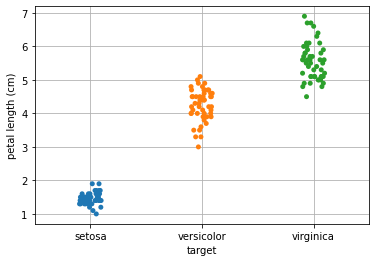

In [29]:
# exploratory data analysis
sns.stripplot(x = 'target', y = 'petal length (cm)', data = df)
plt.grid()

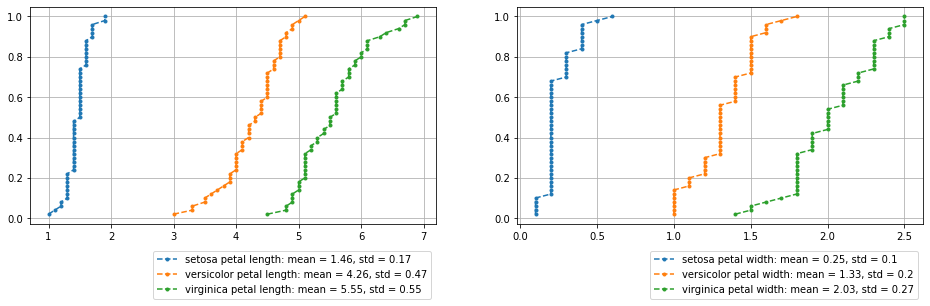

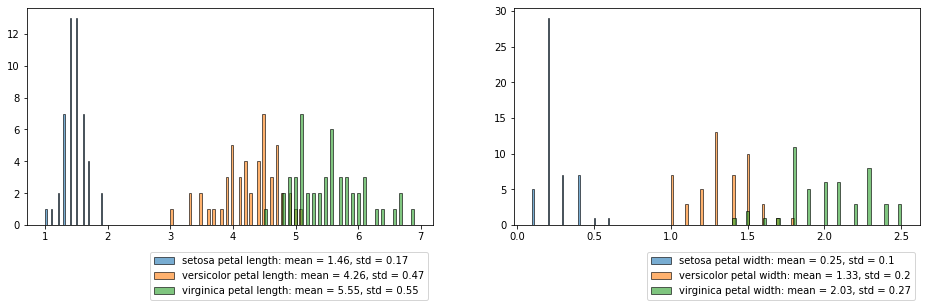

In [174]:
def ecdf(data):
    x = sorted(data)
    y = np.arange(1, len(data) + 1)/len(data)
    return x,y 

fig, ax = plt.subplots(1,2, figsize = [16,4])
for name, data in df.groupby('target'):
    globals()[name+'_pl'] = data['petal length (cm)']        
    x, y = ecdf(globals()[name])    
    ax[0].plot(x, y, 
             marker = '.', 
             linestyle = '--', 
             label = f'{name} petal length: mean = {round(np.mean(globals()[name+"_pl"]),2)}, std = {round(np.std(globals()[name+"_pl"]),2)}')    
    
    globals()[name+'_pw'] = data['petal width (cm)']        
    x, y = ecdf(globals()[name+'_pw'])    
    ax[1].plot(x, y, 
             marker = '.', 
             linestyle = '--', 
             label = f'{name} petal width: mean = {round(np.mean(globals()[name+"_pw"]),2)}, std = {round(np.std(globals()[name+"_pw"]),2)}')    
    globals()[name+'_pw'] = data['petal width (cm)']        

ax[0].legend(bbox_to_anchor= (1,-0.1))        
ax[1].legend(bbox_to_anchor= (1,-0.1))    
ax[0].grid()
ax[1].grid()
plt.show()

fig, ax = plt.subplots(1,2, figsize = [16,4])
for name in df['target'].unique():
    ax[0].hist(globals()[name+'_pl'], 
        alpha = 0.6, 
        bins = 50, 
        label = f'{name} petal length: mean = {round(np.mean(globals()[name+"_pl"]),2)}, std = {round(np.std(globals()[name+"_pl"]),2)}',
        ec = 'k'
            )
    ax[1].hist(globals()[name+'_pw'], 
        alpha = 0.6, 
        bins = 50, 
        label = f'{name} petal width: mean = {round(np.mean(globals()[name+"_pw"]),2)}, std = {round(np.std(globals()[name+"_pw"]),2)}',
        ec = 'k'
            )
        
ax[0].legend(bbox_to_anchor= (1,-0.1))
ax[1].legend(bbox_to_anchor= (1,-0.1))
plt.show()

In [178]:
# analyze setosa petal length and width: mean, var, std

mean_setosa_pl = np.sum(setosa_pl)/len(setosa_pl)
var_setosa_pl = np.sum((setosa_pl - mean_setosa_pl)**2)/len(setosa_pl)
std_setosa_pl = np.sqrt(var_setosa_pl)
print(mean_setosa_pl, var_setosa_pl, std_setosa_pl)

mean_setosa_pw = np.sum(setosa_pw)/len(setosa_pw)
var_setosa_pw = np.sum((setosa_pw - mean_setosa_pw)**2)/len(setosa_pw)
std_setosa_pw = np.sqrt(var_setosa_pw)
print(mean_setosa_pw, var_setosa_pw, std_setosa_pw)

1.4620000000000002 0.029555999999999995 0.17191858538273283
0.24599999999999997 0.010883999999999998 0.1043264108459598


In [189]:
# analyze setosa petal length and width: covariance, pearson
setosa_petal_covar = np.sum(
    ((setosa_pl - mean_setosa_pl) * (setosa_pw - mean_setosa_pw))/len(setosa_pl)
    )
setosa_pearson = setosa_petal_covar/(std_setosa_pl * std_setosa_pw)
setosa_petal_covar, setosa_pearson

(0.005948000000000001, 0.3316300408041188)

In [191]:
# double-checking (as you can see, it's almost identical! I'm proud!):
var_setosa_pl, cov_setosa = np.cov(setosa_pl, setosa_pw, ddof = 0)[0]
cov_setosa, var_setosa_pw = np.cov(setosa_pl, setosa_pw, ddof = 0)[1]
pearson_setosa = np.corrcoef(setosa_pl, setosa_pw)[1,0]
print(var_setosa_pl, var_setosa_pw, cov_setosa, pearson_setosa)

0.029555999999999992 0.010884000000000003 0.005948 0.3316300408041187


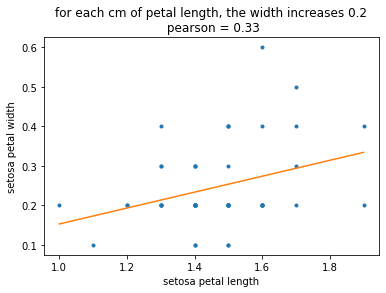

In [207]:
# least squares (legendre?): polyfit
s_slope, s_intercept = np.polyfit(setosa_pl, setosa_pw, deg = 1)
x = np.array([np.min(setosa_pl), np.max(setosa_pl)])
y = x*s_slope + s_intercept
plt.plot(setosa_pl, setosa_pw, marker = '.', linestyle = 'none')
plt.plot(x,y)
plt.xlabel('setosa petal length')
plt.ylabel('setosa petal width')
plt.title(f'for each cm of petal length, the width increases {round(s_slope,2)}\n pearson = {round(pearson_setosa,2)}')
plt.show()

In [ ]:
# next steps: 
# - is this slope by chance or is it real? (permutation of petal widths + p_value)
# - confidence interval of the least square (bootstrap of petal width; 2.5% and 97.5%)